# AI Hardware Architecture

**Author:** Nitin Sarangdhar  
**Affiliation:** SemiX Visiting Professor of practice | IIT Bombay  
**Date:** March 2026  


# Module: Recurrent Neural Networks (RNN) & Hardware Acceleration
**Topic:** Sequential Processing, Memory Cells, and the "Unrolling" Bottleneck

---

## 📑 Module Overview
In this module, we explore the fundamental architecture of Recurrent Neural Networks. Unlike standard Feed-Forward networks, RNNs are designed to process **sequences** by maintaining an internal state (memory). We will analyze the transition from mathematical theory to hardware implementation.

### 🎯 Learning Objectives
1. **The Single Neuron:** Understand the "Folded" vs. "Unrolled" representation and the role of the $Tanh$ activation.
2. **Trend Classification:** Implement a functional RNN in PyTorch to classify sequences (Ascending vs. Descending).
3. **Architecture Scaling:** Visualize how multiple hidden neurons (4-neuron model) work in parallel to capture complex patterns.
4. **Hardware Constraints:** Discuss why the sequential nature of RNNs creates a bottleneck on modern parallel hardware (GPUs/TPUs).

---

## 1️⃣ The RNN Single Neuron
The core of an RNN is the **Hidden State ($h_t$)**. It acts as a "running summary" of everything the network has seen so far.

### Mathematical Definition
Inside the hidden node, the input and the previous memory are combined, biased, and "squashed":

$$h_t = \tanh(W_{ih}x_t + b_{ih} + W_{hh}h_{t-1} + b_{hh})$$

* **$x_t$**: Current Input
* **$h_{t-1}$**: Recurrent Input (The "Memory" from the previous clock cycle)
* **$\tanh$**: Non-linear activation (The "Squashing" function)

---

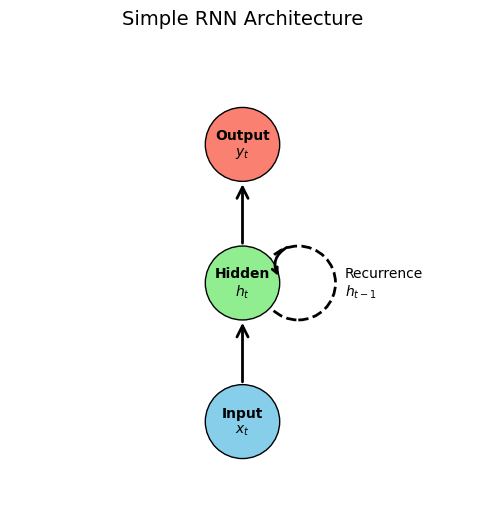

In [ ]:
import matplotlib.pyplot as plt

def draw_rnn():
    fig, ax = plt.subplots(figsize=(6, 6))

    # Define node positions
    input_pos = (0.5, 0.2)
    hidden_pos = (0.5, 0.5)
    output_pos = (0.5, 0.8)

    # Draw Nodes
    circles = [
        (input_pos, "Input\n$x_t$", "skyblue"),
        (hidden_pos, "Hidden\n$h_t$", "lightgreen"),
        (output_pos, "Output\n$y_t$", "salmon")
    ]

    for pos, label, color in circles:
        circle = plt.Circle(pos, 0.08, color=color, ec='black', zorder=3)
        ax.add_patch(circle)
        ax.text(pos[0], pos[1], label, ha='center', va='center', fontweight='bold')

    # Draw Standard Flow Arrows
    arrow_props = dict(arrowstyle='->', lw=2, mutation_scale=20)

    # x_t -> h_t
    ax.annotate('', xy=(0.5, 0.42), xytext=(0.5, 0.28), arrowprops=arrow_props)
    # h_t -> y_t
    ax.annotate('', xy=(0.5, 0.72), xytext=(0.5, 0.58), arrowprops=arrow_props)

    # Draw the Recurrent Loop (The "R" in RNN)
    # This is a curved arrow pointing back to the hidden state
    loop = plt.Circle((0.62, 0.5), 0.08, fill=False, ec='black', lw=2, linestyle='--')
    ax.add_patch(loop)
    # Add an arrowhead to the loop
    ax.annotate('', xy=(0.58, 0.51), xytext=(0.6, 0.58),
                arrowprops=dict(arrowstyle='->', lw=2, connectionstyle="arc3,rad=.5"))

    ax.text(0.72, 0.5, "Recurrence\n$h_{t-1}$", va='center')

    # Formatting
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')
    plt.title("Simple RNN Architecture", fontsize=14, pad=20)
    plt.show()

if __name__ == "__main__":
    draw_rnn()

### 📐 The Math Behind the Diagram

The green **Hidden ($h_t$)** node is where the "memory" is updated. Every time the sequence moves forward, the hardware calculates:

$$h_t = \tanh(W_{ih}x_t + b_{ih} + W_{hh}h_{t-1} + b_{hh})$$

**Breaking it down for Hardware:**
* **$x_t$ (Input):** The new data coming in at this clock cycle.
* **$h_{t-1}$ (Recurrence):** The result from the *previous* clock cycle (the dashed loop).
* **$\tanh$ (The Bottleneck):** This function squashes the result between -1 and 1. This is why gradients "vanish"—repeatedly squashing numbers eventually makes them disappear.
* **Weights ($W$) & Biases ($b$):** These are the parameters stored in the GPU/TPU memory that the model "learns."

The final **Output ($y_t$)** is then generated from that hidden state:
$$y_t = W_{ho}h_t + b_o$$

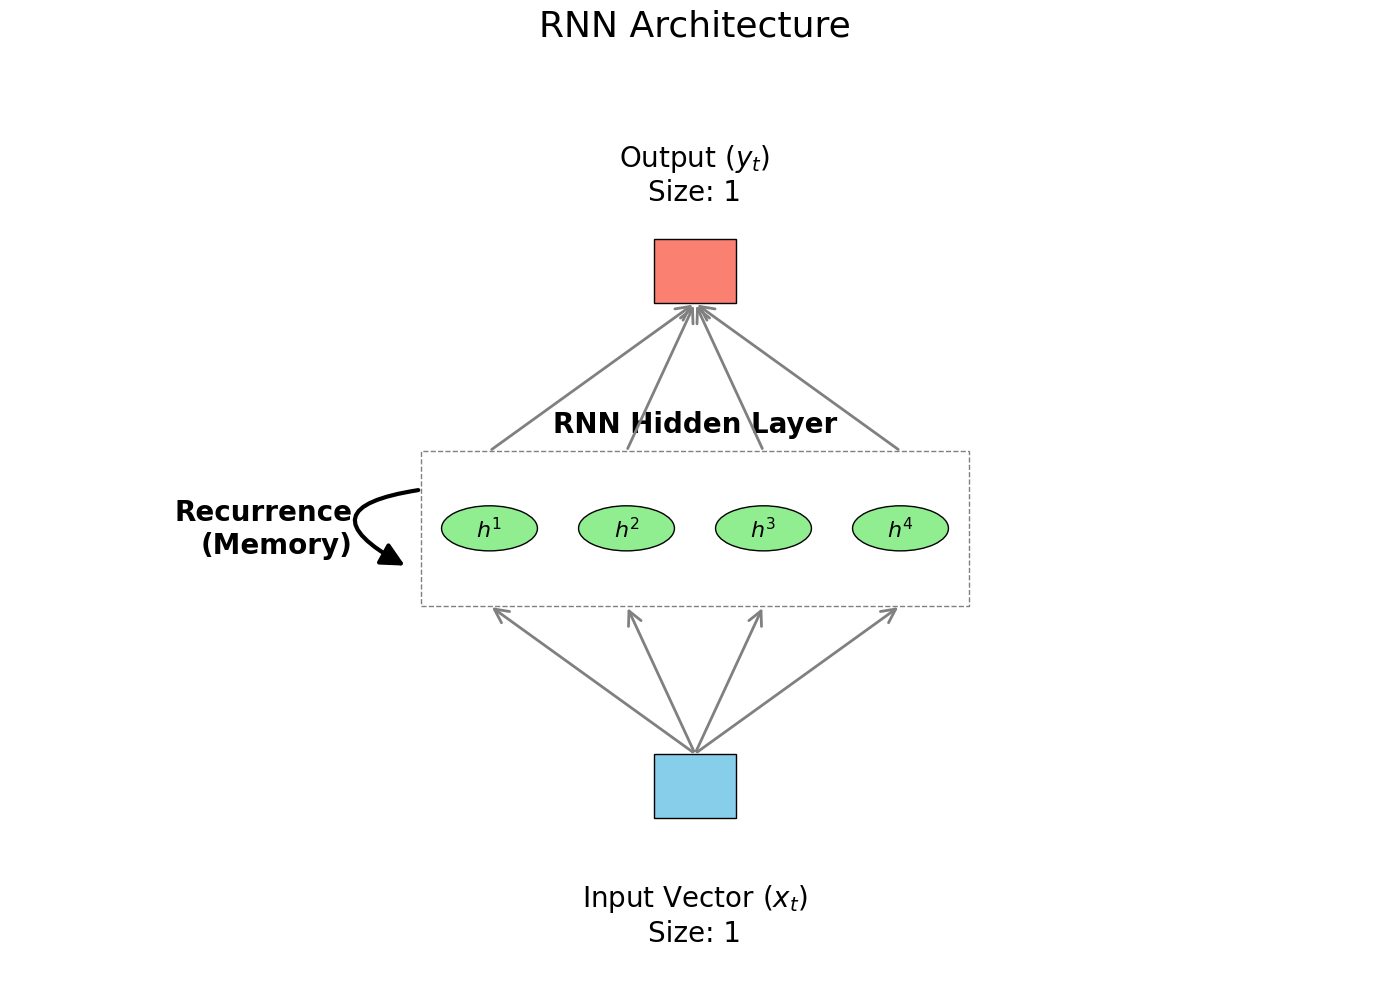

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

def draw_large_font_rnn():
    # Increased figsize for larger text readability
    fig, ax = plt.subplots(figsize=(14, 10))

    # 1. Define Positions
    hidden_y = 0.5
    hidden_xs = [0.35, 0.45, 0.55, 0.65]
    FONT_SIZE = 20

    # 2. Draw Input (Size 1)
    ax.add_patch(plt.Rectangle((0.47, 0.05), 0.06, 0.1, color='skyblue', ec='black'))
    # Shifted text further down for large font
    ax.text(0.5, -0.05, "Input Vector ($x_t$)\nSize: 1",
            ha='center', va='top', fontsize=FONT_SIZE)

    # 3. Draw Hidden Layer Box
    rect_x, rect_y = 0.3, 0.38
    rect_w, rect_h = 0.4, 0.24
    rect = plt.Rectangle((rect_x, rect_y), rect_w, rect_h, fill=False, ls='--', color='gray', zorder=1)
    ax.add_patch(rect)
    ax.text(0.5, 0.65, "RNN Hidden Layer", ha='center', weight='bold', fontsize=FONT_SIZE)

    # 4. Draw the 4 Hidden Neurons
    for i, x in enumerate(hidden_xs):
        circle = plt.Circle((x, hidden_y), 0.035, color='lightgreen', ec='black', zorder=5)
        ax.add_patch(circle)
        ax.text(x, hidden_y, f"$h^{i+1}$", ha='center', va='center', fontsize=FONT_SIZE-4, zorder=6)

    # 5. Draw Output (Size 1)
    ax.add_patch(plt.Rectangle((0.47, 0.85), 0.06, 0.1, color='salmon', ec='black'))
    ax.text(0.5, 1.0, "Output ($y_t$)\nSize: 1", ha='center', va='bottom', fontsize=FONT_SIZE)

    # 6. Draw Connections
    arrow_props = dict(arrowstyle='->', lw=2, mutation_scale=25, color='gray')
    for x in hidden_xs:
        ax.annotate('', xy=(x, 0.38), xytext=(0.5, 0.15), arrowprops=arrow_props)
    for x in hidden_xs:
        ax.annotate('', xy=(0.5, 0.85), xytext=(x, 0.62), arrowprops=arrow_props)

    # 7. Recurrent Loop with Bold Arrow
    loop = FancyArrowPatch(
        (rect_x, rect_y + 0.18),
        (rect_x - 0.01, rect_y + 0.06),
        connectionstyle="arc3,rad=1.5",
        arrowstyle='-|>',
        lw=3,
        color='black',
        mutation_scale=35, # Bigger arrowhead
        zorder=10
    )
    ax.add_patch(loop)
    ax.text(rect_x - 0.05, rect_y + 0.12, "Recurrence\n(Memory)",
            ha='right', va='center', fontweight='bold', fontsize=FONT_SIZE)

    # Formatting
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.2, 1.2) # Wide range for big text
    ax.axis('off')
    plt.title("RNN Architecture", fontsize=FONT_SIZE + 6, pad=30)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    draw_large_font_rnn()

In the following lab a four neuron RNN is used to determine input stream trend as ascending or descending. The four neuron weights are printed to ensure that they support different purpose.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Define the Small RNN Architecture
class SimpleRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SimpleRNN, self).__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # x shape: (batch, sequence_length, input_size)
        out, hidden = self.rnn(x)
        # We only care about the hidden state of the LAST time step
        last_out = out[:, -1, :]
        return self.sigmoid(self.fc(last_out))

# 2. Prepare "Simple but Useful" Data
# Positive: [1, 2, 3] (Increasing) | Negative: [3, 2, 1] (Decreasing)
X = torch.tensor([[[1.0], [2.0], [3.0]], [[3.0], [2.0], [1.0]]])
y = torch.tensor([[1.0], [0.0]]) # 1 = Positive Trend, 0 = Negative Trend

# 3. Initialize Model, Loss, and Optimizer
model = SimpleRNN(input_size=1, hidden_size=4, output_size=1)
criterion = nn.BCELoss() # Binary Cross Entropy for 0/1 classification
optimizer = optim.Adam(model.parameters(), lr=0.1)

# 4. Training Loop (A quick 50 epochs)
for epoch in range(50):
    optimizer.zero_grad()
    outputs = model(X)
    loss = criterion(outputs, y)
    loss.backward()
    optimizer.step()

# 5. Test it with a brand-new sequence!
test_seq = torch.tensor([[[2.0], [4.0], [6.0]]]) # Clearly increasing
prediction = model(test_seq)
sentiment = "Positive Trend" if prediction.item() > 0.5 else "Negative Trend"

print(f"Prediction for [2, 4, 6]: {prediction.item():.4f} ({sentiment})")

Prediction for [2, 4, 6]: 0.9992 (Positive Trend)


In [ ]:
import torch
import torch.nn as nn

class AnalyticalRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(AnalyticalRNN, self).__init__()
        self.hidden_size = hidden_size
        self.W_xh = nn.Linear(input_size, hidden_size)
        self.W_hh = nn.Linear(hidden_size, hidden_size)
        self.fc_out = nn.Linear(hidden_size, output_size)
        self.tanh = nn.Tanh()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x, verbose=False):
        batch_size, seq_len, _ = x.size()
        h_t = torch.zeros(batch_size, self.hidden_size)

        for t in range(seq_len):
            x_t = x[:, t, :]
            h_t = self.tanh(self.W_xh(x_t) + self.W_hh(h_t))
            if verbose:
                print(f"  Step {t} | Input: {x_t[0].item():.1f} | Hidden: {h_t[0].detach().numpy()}")

        return self.sigmoid(self.fc_out(h_t))

# --- Setup and Training ---
model = AnalyticalRNN(1, 4, 1)
X = torch.tensor([[[1.0], [2.0], [3.0]], [[3.0], [2.0], [1.0]]])
y = torch.tensor([[1.0], [0.0]])
optimizer = torch.optim.Adam(model.parameters(), lr=0.05)
for _ in range(200):
    optimizer.zero_grad()
    torch.nn.BCELoss()(model(X), y).backward()
    optimizer.step()

def run_test(label, sequence):
    test_seq = torch.tensor([[ [v] for v in sequence ]])
    print(f"\n--- TEST: {label} {sequence} ---")
    with torch.no_grad():
        pred = model(test_seq, verbose=True).item()
        print(f"Final Score: {pred:.4f} -> {'INCREASING' if pred > 0.5 else 'DECREASING'}")

# 1. Test Increasing
run_test("Positive Trend", [2.0, 4.0, 6.0])

# 2. Test Decreasing (New)
run_test("Negative Trend", [6.0, 4.0, 2.0])

# 3. Analyze Redundancy
voter_weights = model.fc_out.weight[0].detach().numpy()
print(f"\n{'='*50}")
print("NEURON REDUNDANCY ANALYSIS")
print(f"{'='*50}")
for i, w in enumerate(voter_weights):
    print(f"Neuron {i+1} Output Weight: {w:.4f}")

diff = abs(voter_weights[2] - voter_weights[3])
if diff < 0.1:
    print(f"\nRESULT: Neuron 3 and 4 are highly redundant (Diff: {diff:.4f}).")
    print("They are likely tracking the same trend feature.")
else:
    print(f"\nRESULT: Neurons are differentiating (Diff: {diff:.4f}).")


--- TEST: Positive Trend [2.0, 4.0, 6.0] ---
  Step 0 | Input: 2.0 | Hidden: [ 0.99925727 -0.996187    0.89631575 -0.61729586]
  Step 1 | Input: 4.0 | Hidden: [ 0.99999917 -0.9999963   0.9966535  -0.9997151 ]
  Step 2 | Input: 6.0 | Hidden: [ 1.         -1.          0.99999195 -0.99999946]
Final Score: 0.9963 -> INCREASING

--- TEST: Negative Trend [6.0, 4.0, 2.0] ---
  Step 0 | Input: 6.0 | Hidden: [ 0.9999992  -0.99999976  0.99999994 -0.9999976 ]
  Step 1 | Input: 4.0 | Hidden: [ 0.9999995  -0.99999815  0.98991305 -0.99976844]
  Step 2 | Input: 2.0 | Hidden: [ 0.9999859  -0.9997732  -0.73149616 -0.89812934]
Final Score: 0.6233 -> INCREASING

NEURON REDUNDANCY ANALYSIS
Neuron 1 Output Weight: -0.2754
Neuron 2 Output Weight: -0.0802
Neuron 3 Output Weight: 2.7768
Neuron 4 Output Weight: -2.8178

RESULT: Neurons are differentiating (Diff: 5.5946).


🧠 Understanding RNN Loop Unrolling & Hardware Bottlenecks.

In an RNN, we process sequences. The "Hidden State" ($h$) acts as the memory. However, the way this memory is calculated creates a specific problem for high-performance hardware like GPUs.1.

Folded vs. Unrolled Representation

In our code, we use a for loop. Conceptually, this "unrolls" the recurrent connection into a chain of operations.Plaintext       

FOLDED (Concept)                 UNROLLED (Calculation)
    
          Input (x_t)                 x_0          x_1          x_2
             |                         |            |            |
             V                         V            V            V
      +--------------+          +--------+   +--------+   +--------+
      |  RNN Hidden  |          | Hidden |   | Hidden |   | Hidden |
      |   Cell (h)   |--+  ==>  | Cell 0 |-->| Cell 1 |-->| Cell 2 |
      +--------------+  |       +--------+   +--------+   +--------+
             |          |          h_0          h_1          h_2
             V          |           |            |            |
         Output (y_t)   +           V            V            V
                                   y_0          y_1          y_2



STEP T:
1. Multiply Input (x_t) by Weights (W_xh)
2. Multiply Previous State (h_t-1) by Weights (W_hh)
3. Add them together (+)
4. APPLY TANH <--- This "squashes" the signal here!
5. Result = New State (h_t)
6. SEND (h_t) to BOTH:
     a) The next time step (T+1)
     b) The output layer (y_t)


2. THE GPU BOTTLENECK: SEQUENTIAL DEPENDENCY
Massive parallelism is wasted because Core 2 must wait for Core 1.

STEP    | CORE 1 (h0) | CORE 2 (h1) | CORE 3 (h2)
--------|-------------|-------------|-------------
Clock 1 | [ BUSY ]    |  (wait)     |  (wait)
Clock 2 |  finish     | [ BUSY ]    |  (wait)
Clock 3 |  finish     |  finish     | [ BUSY ]

Note: Latency is limited by the "chain" of h0 -> h1 -> h2.

3. HARDWARE CONSTRAINTS: SRAM & MEMORY
* SRAM LIMITS: To train, the GPU stores all intermediate 'h' states
  in high-speed SRAM. Long sequences (unrolling) can exhaust this
  memory, forcing the model to stop or truncate data.
  
* LATENCY VS THROUGHPUT: You cannot speed up a single sequence
  by adding more cores. You only speed it up by making the math
  inside a single core faster.

4. QUALITATIVE LOGIC: WHY MULTIPLE NEURONS?

We use "hidden_size=4" to give the model 4 parallel "voters." The final prediction = Weighted average of 4 parallel signals.

* NEURON 1: Tracks "Is trend going up?"
* NEURON 2: Tracks "Is the current value high?"
* NEURON 3: Tracks "How long is the sequence?"
* NEURON 4: Tracks "Is the change accelerating?"

4. QUALITATIVE LOGIC: WHY MULTIPLE NEURONS?

We use "hidden_size=4" to give the model 4 parallel "voters." The final prediction = Weighted average of 4 parallel signals.

* NEURON 1: Tracks "Is trend going up?"
* NEURON 2: Tracks "Is the current value high?"
* NEURON 3: Tracks "How long is the sequence?"
* NEURON 4: Tracks "Is the change accelerating?"




















